<a href="https://colab.research.google.com/github/FallingFrost/robotics-practice/blob/main/apple_detection_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 苹果检测 · Colab（Stage 2）

**只含 detection 线**：构建 YOLO 标签 → 训练 YOLO26 → COCO AP 评估（含 AP_small）→ 推理可视化。
**不含 counting 数据集**的任何训练 / 推理代码，也不会下载或构建 counting 缓存。

**前置**
1. 数据集已放在 Google Drive：`detection/train/{images,masks}`、`detection/test/images`、
   `test_data/detection/ground_truth.json`。
2. 代码包 `apple_detection_code.zip` 放到 Drive 的 `MyDrive/apple_detection/`，
   或直接上传到 Colab 的 `/content/`。

**Drive 数据布局**（`<DATA_ROOT>` 满足其一即可；外面多包一层 `data/` 也认）：

```
<DATA_ROOT>/
├─ detection/
│  ├─ train/images/   670 PNG
│  ├─ train/masks/    670 实例 ID 掩膜（uint8，0=背景）
│  └─ test/images/    331 PNG
└─ test_data/detection/ground_truth.json
```

找不到会自动在 `MyDrive` 里浅层搜索（≤4 层，最多 300 个目录）；
仍找不到就把 cell 1 的 `DATA_ROOT` 写成 Drive 上的真实路径。
只放了 `detection.tar.gz` + `test_data.zip` 也行，notebook 会在本地解压。

**可选：已经训好的权重。** 把 `best.pt` 传到 `MyDrive/apple_detection/`
（根目录或 `weights/` 下都行），cell 1 会自动认领。这样 **cell 5 训练可以整段跳过**
（把 cell 5 的 `TRAIN` 取消勾选即可，Run all 也不会训），直接跑 cell 6 评估 / cell 7 推理。


In [9]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [10]:
#@title 1. 挂载 Drive，定位代码包与数据集
import pathlib

PROJ = pathlib.Path('/content/apple_detection')     # 代码解压到这里
MYDRIVE = pathlib.Path('/content/drive/MyDrive')

# ⚠️ 自动找不到数据时，把这里改成 Drive 上含 detection/ 与 test_data/ 的目录
DATA_ROOT = None

# 代码包候选（新的 detection 专用包；最后一项兼容旧的混合包）
ZIP_CANDIDATES = [
    PROJ / 'apple_detection_code.zip',
    pathlib.Path('/content/apple_detection_code.zip'),
    MYDRIVE / 'apple_detection' / 'apple_detection_code.zip',
    MYDRIVE / 'apple_counting' / 'apple_detection_code.zip',
    MYDRIVE / 'apple_counting' / 'apple_counting_code.zip',
    MYDRIVE / 'machine learning project' / 'colab' / 'apple_detection_code.zip',
    MYDRIVE / 'machine learning project' / 'colab' / 'apple_counting_code.zip',
]

try:
    from google.colab import drive
    drive.mount('/content/drive')
except Exception as exc:
    raise SystemExit('Drive 挂载失败（本 notebook 假定在 Colab 运行）：' + str(exc))


def is_dataset_root(p):
    p = pathlib.Path(p)
    return all([
        (p / 'detection/train/images').is_dir(),
        (p / 'detection/train/masks').is_dir(),
        (p / 'detection/test/images').is_dir(),
        (p / 'test_data/detection/ground_truth.json').is_file(),
    ])


def normalize_root(p):
    """同时接受 <root>/detection 与 <root>/data/detection 两种布局。"""
    if p is None:
        return None
    p = pathlib.Path(p)
    for cand in (p, p / 'data'):
        if is_dataset_root(cand):
            return cand
    return None


SRC_ZIP = next((p for p in ZIP_CANDIDATES if p.exists()), None)

DATA_ROOT = normalize_root(DATA_ROOT)

if DATA_ROOT is None:
    for cand in [
        MYDRIVE / 'apple_detection' / 'data',
        MYDRIVE / 'apple_detection',
        MYDRIVE / 'apple_counting' / 'data',
        MYDRIVE / 'apple_counting',
        MYDRIVE / 'MinneApple' / 'data',
        MYDRIVE / 'MinneApple',
        MYDRIVE / 'machine learning project' / 'Apple Counting',
        MYDRIVE / 'data',
        MYDRIVE,
    ]:
        DATA_ROOT = normalize_root(cand)
        if DATA_ROOT:
            break

if DATA_ROOT is None:
    print('已知位置没有，正在 MyDrive 里浅层搜索（≤4 层，最多 300 个目录）…')
    stack, seen = [(MYDRIVE, 0)], 0
    while stack and DATA_ROOT is None and seen < 300:
        d, depth = stack.pop()
        seen += 1
        DATA_ROOT = normalize_root(d)
        if DATA_ROOT or depth >= 4:
            continue
        try:
            kids = sorted(c for c in d.iterdir()
                          if c.is_dir() and not c.name.startswith('.'))
        except OSError:
            continue
        stack.extend((c, depth + 1) for c in kids)
    print(f'  搜索了 {seen} 个目录')

print('代码包：', SRC_ZIP or '未找到')
print('数据根：', DATA_ROOT or '未找到')
if DATA_ROOT:
    n_tr = sum(1 for _ in (DATA_ROOT / 'detection/train/images').glob('*.png'))
    n_te = sum(1 for _ in (DATA_ROOT / 'detection/test/images').glob('*.png'))
    print(f'  train 图 {n_tr}   test 图 {n_te}')

# 只放了压缩包时的兜底位置
ARCHIVE_DIRS = [d for d in (DATA_ROOT, MYDRIVE / 'apple_detection',
                            MYDRIVE / 'apple_counting', MYDRIVE) if d]
DET_TAR = next((d / 'detection.tar.gz' for d in ARCHIVE_DIRS
                if (d / 'detection.tar.gz').exists()), None)
TEST_ZIP = next((d / 'test_data.zip' for d in ARCHIVE_DIRS
                 if (d / 'test_data.zip').exists()), None)
if DATA_ROOT is None:
    print('压缩包：', DET_TAR, TEST_ZIP)

# 已经训练好的权重（可选）：传到 Drive 后自动认领，用来直接做评估 / 推理，跳过训练。
# 放到 MyDrive/apple_detection/best.pt 或 .../weights/best.pt 都行。
WEIGHTS_CANDIDATES = [
    MYDRIVE / 'apple_detection' / 'weights' / 'best.pt',
    MYDRIVE / 'apple_detection' / 'best.pt',
    MYDRIVE / 'apple_detection' / 'd1_yolo26s_b32' / 'weights' / 'best.pt',
    MYDRIVE / 'apple_detection' / 'runs' / 'detection' / 'd1_yolo26s_b32' / 'weights' / 'best.pt',
    MYDRIVE / 'apple_counting' / 'weights' / 'best.pt',
    MYDRIVE / 'apple_counting' / 'best.pt',
    MYDRIVE / 'apple_counting' / 'd1_yolo26s_b32' / 'weights' / 'best.pt',
]
PRETRAINED_WEIGHTS = next((p for p in WEIGHTS_CANDIDATES if p.exists()), None)

if PRETRAINED_WEIGHTS is None:
    # 浅层找 *.pt（不递归整个 Drive）
    for base in (MYDRIVE / 'apple_detection', MYDRIVE / 'apple_counting'):
        if not base.is_dir():
            continue
        # 优先 best*.pt，避免误把 yolo26s.pt（COCO 预训练）当成训练产物
        for pat in ('weights/best*.pt', 'best*.pt', '*/*/weights/best*.pt',
                    'weights/*.pt', '*.pt', '*/*.pt', '*/weights/*.pt',
                    '*/*/weights/*.pt'):
            hits = sorted(base.glob(pat))
            if hits:
                PRETRAINED_WEIGHTS = hits[0]
                break
        if PRETRAINED_WEIGHTS:
            break

print('预训练权重：', PRETRAINED_WEIGHTS or '未找到（可用 EXTERNAL_WEIGHTS 手动指定）')
if PRETRAINED_WEIGHTS:
    print(f'  文件 {PRETRAINED_WEIGHTS.stat().st_size / 1e6:.1f} MB'
          f'（yolo26s 的 best.pt 约 20 MB）')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
已知位置没有，正在 MyDrive 里浅层搜索（≤4 层，最多 300 个目录）…
  搜索了 7 个目录
代码包： /content/apple_detection_code.zip
数据根： 未找到
压缩包： /content/drive/MyDrive/apple_counting/detection.tar.gz /content/drive/MyDrive/apple_counting/test_data.zip
预训练权重： /content/drive/MyDrive/apple_counting/weights/best.pt
  文件 20.4 MB（yolo26s 的 best.pt 约 20 MB）


In [11]:
#@title 2. 环境检查 + 安装锁定版本
import importlib.metadata as md
import importlib.util
import subprocess
import sys

!nvidia-smi --query-gpu=name,memory.total,driver_version --format=csv

import torch
print('python', sys.version.split()[0], '| torch', torch.__version__,
      '| cuda', torch.cuda.is_available())
if torch.cuda.is_available():
    p = torch.cuda.get_device_properties(0)
    print('GPU:', p.name, f'{p.total_memory / 1e9:.1f} GB')
else:
    print('⚠️ 没拿到 GPU：运行时 → 更改运行时类型 → T4 GPU')

ULTRALYTICS_PIN = '8.4.177'      # YOLO26 从 8.4.0 才有；版本变动会改精度


def _version(pkg):
    try:
        return md.version(pkg)
    except md.PackageNotFoundError:
        return None


def _major(v):
    return int(v.split('.')[0]) if v else -1


# polars 2.x 没在 8.4.177 上验证过；本机成功环境是 1.31
if (_version('ultralytics') != ULTRALYTICS_PIN or _version('polars') is None
        or _major(_version('polars')) >= 2):
    print(f'安装 ultralytics=={ULTRALYTICS_PIN} + polars<2 …')
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
                    f'ultralytics=={ULTRALYTICS_PIN}', 'polars<2'], check=True)
if importlib.util.find_spec('pycocotools') is None:
    print('安装 pycocotools …')
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
                    'pycocotools'], check=True)
if importlib.util.find_spec('scipy') is None:       # mask_to_boxes 用 ndimage
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
                    'scipy'], check=True)

import cv2
import ultralytics
print('ultralytics', ultralytics.__version__, '| pycocotools', _version('pycocotools'),
      '| opencv', cv2.__version__)


name, memory.total [MiB], driver_version
Tesla T4, 15360 MiB, 580.82.07
python 3.13.15 | torch 2.11.0+cu130 | cuda True
GPU: Tesla T4 15.6 GB
ultralytics 8.4.177 | pycocotools 2.0.11 | opencv 4.14.0


In [12]:
#@title 3. 解压代码
import shutil
import zipfile

assert SRC_ZIP is not None, (
    '找不到代码包。把它放到下面任一路径，或改 cell 1 的 ZIP_CANDIDATES：\n  '
    + '\n  '.join(str(p) for p in ZIP_CANDIDATES))

# ⚠️ 不能整个 rmtree(PROJ)：zip 可能就放在 PROJ 里，整删会把它一起删掉。
# 只清掉 zip 会覆盖的两个目录。Apple Counting/data 是符号链接，rmtree 不会跟进去。
for sub in ('common', 'Apple Counting'):
    p = PROJ / sub
    if p.is_symlink():
        p.unlink()
    elif p.exists():
        shutil.rmtree(p)
PROJ.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(SRC_ZIP) as z:
    z.extractall(PROJ)

print(f'代码已从 {SRC_ZIP} 解压到 {PROJ}')
DET_SCRIPTS = ['build_detection_labels.py', 'check_detection.py', 'train_detection.py',
               'eval_detection.py', 'infer_detection.py']
print('detection 脚本：')
for name in DET_SCRIPTS:
    p = PROJ / 'Apple Counting/src' / name
    assert p.exists(), f'代码包缺 {name}'
    print('  ', name)
assert (PROJ / 'common/paths.py').exists(), '代码包结构不对：缺 common/paths.py'
assert (PROJ / 'Apple Counting/cache/detection_index.csv').exists(), \
    '代码包缺 Apple Counting/cache/detection_index.csv'


代码已从 /content/apple_detection_code.zip 解压到 /content/apple_detection
detection 脚本：
   build_detection_labels.py
   check_detection.py
   train_detection.py
   eval_detection.py
   infer_detection.py


只找到压缩包，就地解压到本地 SSD …
本地数据： {'train 图': 670, 'train 掩膜': 670, 'test 图': 331, 'test GT': 1}
数据链接： /content/apple_detection/Apple Counting/data -> /content/detection_data

▶ 构建 YOLO 标签与切分
  /usr/bin/python3 /content/apple_detection/Apple Counting/src/build_detection_labels.py
✓ 构建 YOLO 标签与切分 完成，7s

▶ 数据层六项体检
  /usr/bin/python3 /content/apple_detection/Apple Counting/src/check_detection.py
✓ 数据层六项体检 完成，2s

切分： {'train': 611, 'val': 59, 'test': 331}
框数： {'train': 26028, 'val': 2154, 'test': 12285}
val 序列： ['20150921_131234']


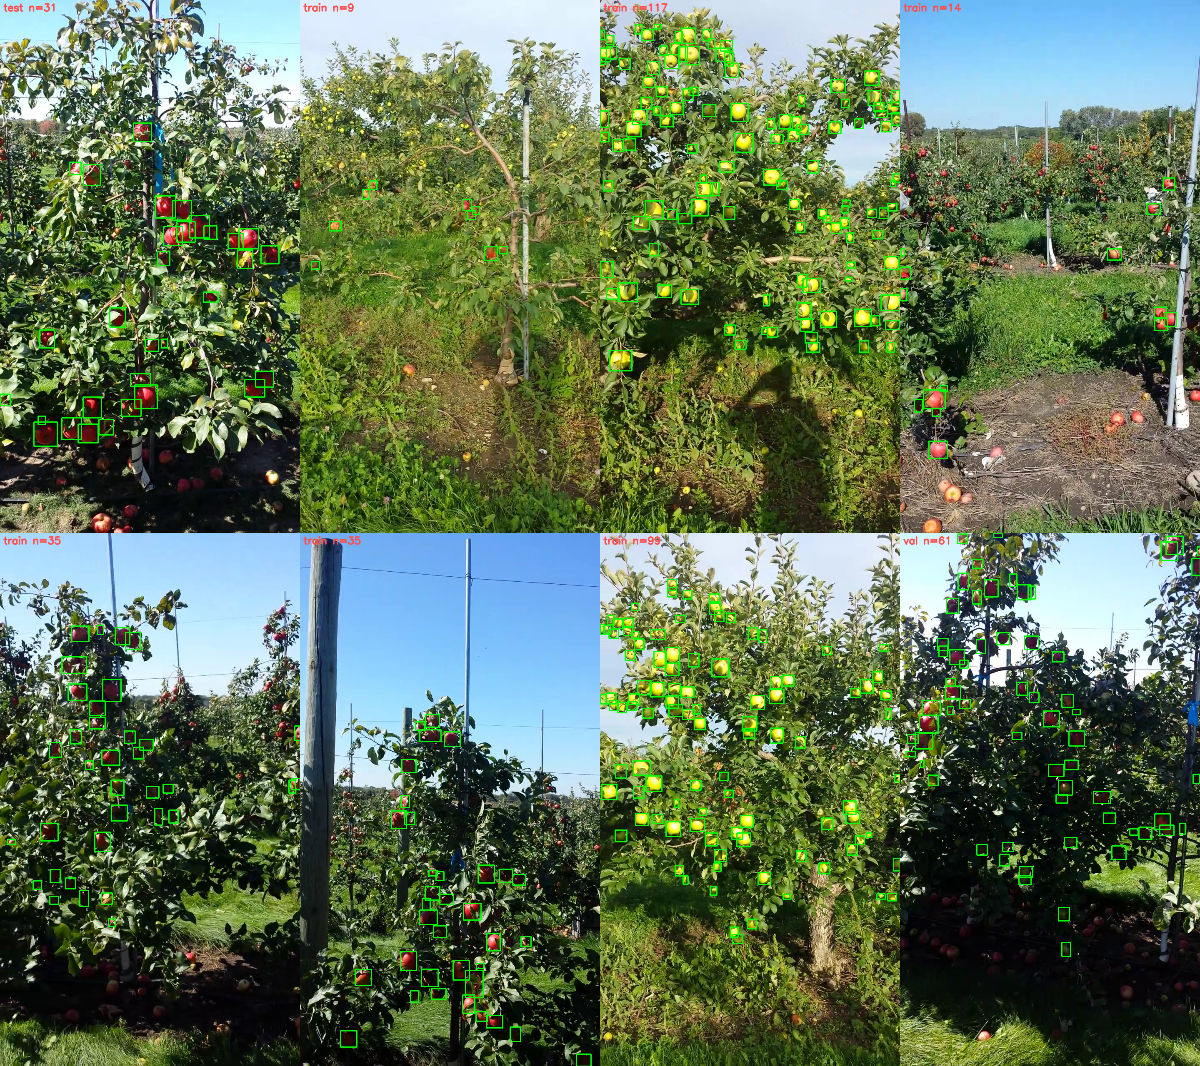

In [13]:
#@title 4. 数据就位 + 构建 YOLO 标签 + 六项体检
import json
import os
import pathlib
import shutil
import subprocess
import sys
import tarfile
import time
import zipfile

APPLE = PROJ / 'Apple Counting'
LOCAL_DATA = pathlib.Path('/content/detection_data')   # Colab 本地 SSD
DATA_LINK = APPLE / 'data'
N_TRAIN, N_TEST = 670, 331


def count_png(d):
    d = pathlib.Path(d)
    return sum(1 for _ in d.glob('*.png')) if d.is_dir() else 0


def data_complete():
    # 用 >=：Drive 目录里多出来的杂图不影响；真正用的是 detection_index.csv 里的 1001 条
    return (count_png(LOCAL_DATA / 'detection/train/images') >= N_TRAIN
            and count_png(LOCAL_DATA / 'detection/train/masks') >= N_TRAIN
            and count_png(LOCAL_DATA / 'detection/test/images') >= N_TEST
            and (LOCAL_DATA / 'test_data/detection/ground_truth.json').is_file())


def copy_files(src, dst, label):
    """逐文件复制，同尺寸跳过；带进度（Drive 上 1000+ 个小文件能等很久）。"""
    src, dst = pathlib.Path(src), pathlib.Path(dst)
    dst.mkdir(parents=True, exist_ok=True)
    files = sorted(p for p in src.iterdir() if p.is_file())
    t0 = time.time()
    for i, p in enumerate(files, 1):
        q = dst / p.name
        if not (q.exists() and q.stat().st_size == p.stat().st_size):
            shutil.copy2(p, q)
        if i % 200 == 0 or i == len(files):
            print(f'    {label:<10}{i:>4}/{len(files)}  {time.time() - t0:.0f}s',
                  flush=True)


if data_complete():
    print('本地已有完整数据，跳过复制：', LOCAL_DATA)
else:
    if LOCAL_DATA.exists():
        shutil.rmtree(LOCAL_DATA)
    LOCAL_DATA.mkdir(parents=True, exist_ok=True)

    if DATA_ROOT is not None:
        print('从 Drive 复制到本地 SSD（一次性，约 1.8 GB）…')
        copy_files(DATA_ROOT / 'detection/train/images',
                   LOCAL_DATA / 'detection/train/images', 'train 图')
        copy_files(DATA_ROOT / 'detection/train/masks',
                   LOCAL_DATA / 'detection/train/masks', 'train 掩膜')
        copy_files(DATA_ROOT / 'detection/test/images',
                   LOCAL_DATA / 'detection/test/images', 'test 图')
        gt = LOCAL_DATA / 'test_data/detection/ground_truth.json'
        gt.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(DATA_ROOT / 'test_data/detection/ground_truth.json', gt)
    elif DET_TAR is not None and TEST_ZIP is not None:
        print('只找到压缩包，就地解压到本地 SSD …')
        with tarfile.open(DET_TAR) as tf:
            members = [m for m in tf.getmembers() if m.name.startswith('detection/')]
            try:
                tf.extractall(LOCAL_DATA, members=members, filter='data')
            except TypeError:                      # Python < 3.12 没有 filter 参数
                tf.extractall(LOCAL_DATA, members=members)
        with zipfile.ZipFile(TEST_ZIP) as z:
            z.extractall(LOCAL_DATA, [n for n in z.namelist()
                                      if n.startswith('test_data/detection/')])
    else:
        raise SystemExit(
            '既没找到解压好的数据集，也没找到 detection.tar.gz + test_data.zip。\n'
            '把 cell 1 的 DATA_ROOT 改成 Drive 上含 detection/ 与 test_data/ 的目录。')

counts = {
    'train 图': count_png(LOCAL_DATA / 'detection/train/images'),
    'train 掩膜': count_png(LOCAL_DATA / 'detection/train/masks'),
    'test 图': count_png(LOCAL_DATA / 'detection/test/images'),
    'test GT': int((LOCAL_DATA / 'test_data/detection/ground_truth.json').is_file()),
}
print('本地数据：', counts)
if not data_complete():
    print('⚠️ 数量不是 670/670/331/1。如果你用别的切分，请改 N_TRAIN / N_TEST；'
          '否则先检查 Drive 上的数据是否完整。')
    raise SystemExit('数据不完整')

# 让 paths.py 里的 <Apple Counting>/data 指向本地 SSD
if DATA_LINK.is_symlink():
    DATA_LINK.unlink()
elif DATA_LINK.exists():
    shutil.rmtree(DATA_LINK)
os.symlink(LOCAL_DATA, DATA_LINK, target_is_directory=True)
print('数据链接：', DATA_LINK, '->', os.readlink(DATA_LINK))


def run_step(title, script, *extra):
    cmd = [sys.executable, str(APPLE / 'src' / script), *extra]
    print(f'\n▶ {title}')
    print('  ' + ' '.join(cmd))
    t0 = time.time()
    r = subprocess.run(cmd, cwd=str(PROJ))
    if r.returncode != 0:
        raise SystemExit(f'✗ {title} 失败（exit {r.returncode}）')
    print(f'✓ {title} 完成，{time.time() - t0:.0f}s')


# 4 秒左右：掩膜 → YOLO 标签，按视频序列切 train/val，并把 test COCO 转成标签
run_step('构建 YOLO 标签与切分', 'build_detection_labels.py')
# 六项体检：含「标签 ↔ 掩膜往返」和「序列泄漏」，这两项最容易静默出错
run_step('数据层六项体检', 'check_detection.py')

meta = json.loads((APPLE / 'cache/detection/labels_meta.json').read_text(encoding='utf-8'))
print('\n切分：', meta['counts'])
print('框数：', meta['boxes'])
print('val 序列：', meta['val_seqs'])

# 体检拼图：绿框 = YOLO 标签反算的框，肉眼确认没有串位
from IPython.display import Image, display
montage = APPLE / 'cache/detection/check_detection_montage.png'
if montage.exists():
    display(Image(filename=str(montage), width=900))


In [15]:
#@title 5. 训练（YOLO26）
import pathlib
import subprocess
import sys
import time

MODEL = 'yolo26s'   #@param ["yolo26s", "yolo26n", "yolo26m", "yolo26s-p2", "yolo11s", "yolov8s"]
EPOCHS = 60         #@param {type:"integer"}
IMGSZ = 1280        #@param [640, 960, 1280]
BATCH = 8           #@param {type:"integer"}
WORKERS = 2         #@param {type:"integer"}
SMOKE = False       #@param {type:"boolean"}
# 已有训好的权重时取消勾选：整段跳过训练，cell 6 直接找本地/Drive 上的 best.pt
TRAIN = False        #@param {type:"boolean"}

RUN_NAME = f'colab_t4_{MODEL}_{EPOCHS}ep'
if not TRAIN:
    print('TRAIN=False：跳过训练。cell 6 会用 cell 1 找到的 Drive 权重（或本地已有 run）。')
else:
    cmd = [sys.executable, str(APPLE / 'src' / 'train_detection.py'),
           '--model', MODEL, '--epochs', str(EPOCHS), '--imgsz', str(IMGSZ),
           '--batch', str(BATCH), '--workers', str(WORKERS), '--name', RUN_NAME]
    if SMOKE:
        cmd.append('--smoke')

    print(' '.join(cmd))
    print('（T4 16 GB：imgsz 1280 下 batch 8 可能触发 ultralytics 自动减半；')
    print('  日志里搜 "Reducing to batch=" 看真正生效的批大小。有效批大小恒为 64，')
    print('  改 batch 只影响吞吐，不改变优化动力学。）')
    t0 = time.time()
    r = subprocess.run(cmd, cwd=str(PROJ))
    print(f'\n训练进程退出码 {r.returncode}，墙钟 {(time.time() - t0) / 60:.1f} 分钟')
    if r.returncode != 0:
        raise SystemExit('训练失败，看上面的日志。')


TRAIN=False：跳过训练。cell 6 会用 cell 1 找到的 Drive 权重（或本地已有 run）。


In [16]:
#@title 6. 评估（COCO AP，含 AP_small）
import json
import pathlib
import subprocess
import sys
import time

RUN_NAME = globals().get('RUN_NAME', '')
IMGSZ = globals().get('IMGSZ', 1280)
# 留空 = 用本次训练产出的 best.pt；也可填 Drive 上已有权重的路径，跳过训练直接评估
EXTERNAL_WEIGHTS = ''   #@param {type:"string"}
# 整图计数块用的阈值；0.40 = 项目定案的最终方案 T0.40（AP 本身与它无关）
COUNT_CONF = 0.40       #@param {type:"number"}

run_dir_hint = APPLE / 'runs' / 'detection' / RUN_NAME if RUN_NAME else None

if EXTERNAL_WEIGHTS.strip():
    WEIGHTS = pathlib.Path(EXTERNAL_WEIGHTS)
    if not WEIGHTS.exists():
        raise SystemExit(f'EXTERNAL_WEIGHTS 不存在：{WEIGHTS}')
elif run_dir_hint and (run_dir_hint / 'weights' / 'best.pt').exists():
    WEIGHTS = run_dir_hint / 'weights' / 'best.pt'
else:
    cands = sorted((APPLE / 'runs' / 'detection').glob('*/weights/best.pt'),
                   key=lambda p: p.stat().st_mtime)
    if cands:
        WEIGHTS = cands[-1]
        print('⚠️ 本次 RUN_NAME 没有 best.pt，改用本地最新的：', WEIGHTS)
    elif globals().get('PRETRAINED_WEIGHTS'):
        WEIGHTS = PRETRAINED_WEIGHTS
        print('没训练也可以：用 Drive 上已传好的权重', WEIGHTS)
    else:
        raise SystemExit('找不到 best.pt：先跑 cell 5，或把权重传到 Drive 的 '
                         'MyDrive/apple_detection/ 并重跑 cell 1，或填 EXTERNAL_WEIGHTS')

WEIGHTS = pathlib.Path(WEIGHTS)
RUN_DIR = WEIGHTS.parent.parent if WEIGHTS.parent.name == 'weights' else WEIGHTS.parent
RUN_NAME = RUN_DIR.name
print('权重：', WEIGHTS)

cmd = [sys.executable, str(APPLE / 'src' / 'eval_detection.py'),
       '--weights', str(WEIGHTS), '--split', 'test', '--imgsz', str(IMGSZ),
       '--count-conf', str(COUNT_CONF)]
print(' '.join(cmd))
t0 = time.time()
r = subprocess.run(cmd, cwd=str(PROJ))
print(f'\n评估进程退出码 {r.returncode}，{(time.time() - t0) / 60:.1f} 分钟')
if r.returncode != 0:
    raise SystemExit('评估失败，看上面的日志。')

res = json.loads((APPLE / 'cache/detection/eval_test.json').read_text(encoding='utf-8'))
o, a = res['overall'], res['anchors']


def fmt(v):
    return ' n/a  ' if v is None else f'{v:.4f}'


def line(name, key):
    v = o[key]
    if v is None:
        print(f'  {name:<12} n/a（该尺寸桶没有真值）')
    else:
        print(f'  {name:<12} {v:.4f}   论文 {a[key]:.3f}   {v - a[key]:+.4f}')


print('\n=== test（与论文同口径，pycocotools）===')
line('AP', 'AP')
line('AP@0.5', 'AP50')
line('AP_small', 'AP_small')
print(f'  AP@0.75 {fmt(o["AP75"])}   AP_medium {fmt(o["AP_medium"])}   '
      f'AR@100 {fmt(o["AR_100"])}')
print(f'  预测框 {o["n_pred"]}   真值框 {o["n_gt"]}')

print('\n=== 分段 ===')
for g, m in res['per_group'].items():
    if m:
        print(f'  {g:<10} AP {fmt(m["AP"])}  AP50 {fmt(m["AP50"])}  '
              f'AP_small {fmt(m["AP_small"])}')

c = res['counting']
print('\n=== 整图计数（conf {}，⚠️ 真值口径有坑）==='.format(res['conf_count']))
print(f'  真值 {c["gt_total"]}  预测 {c["pred_total"]}  '
      f'偏差 {c["pred_total"] - c["gt_total"]:+.0f}  MAE {c["mae"]:.2f}  '
      f'完全正确 {c["exact_match"]:.1%}')


没训练也可以：用 Drive 上已传好的权重 /content/drive/MyDrive/apple_counting/weights/best.pt
权重： /content/drive/MyDrive/apple_counting/weights/best.pt
/usr/bin/python3 /content/apple_detection/Apple Counting/src/eval_detection.py --weights /content/drive/MyDrive/apple_counting/weights/best.pt --split test --imgsz 1280 --count-conf 0.4

评估进程退出码 0，1.1 分钟

=== test（与论文同口径，pycocotools）===
  AP           0.4519   论文 0.438   +0.0139
  AP@0.5       0.7945   论文 0.775   +0.0195
  AP_small     0.3119   论文 0.297   +0.0149
  AP@0.75 0.4722   AP_medium 0.6091   AR@100 0.5431
  预测框 91824   真值框 12285

=== 分段 ===
  dataset1   AP 0.4538  AP50 0.7577  AP_small 0.2674
  dataset2   AP 0.4564  AP50 0.7615  AP_small 0.2482
  dataset3   AP 0.4518  AP50 0.8057  AP_small 0.3016
  dataset4   AP 0.4501  AP50 0.8526  AP_small 0.3978

=== 整图计数（conf 0.4，⚠️ 真值口径有坑）===
  真值 12285  预测 11675  偏差 -610  MAE 6.03  完全正确 7.9%


从 test 抽 8 张：['dataset1_back_1.png', 'dataset1_back_1021.png', 'dataset2_back_0.png', 'dataset2_back_1020.png', 'dataset3_back_0.png', 'dataset3_back_1020.png', 'dataset4_front_0.png', 'dataset4_front_1020.png']
/usr/bin/python3 /content/apple_detection/Apple Counting/src/infer_detection.py --weights /content/drive/MyDrive/apple_counting/weights/best.pt --source /content/infer_demo_input --out /content/apple_detection/Apple Counting/runs/detection/infer_demo_apple_counting --conf 0.4

推理进程退出码 0，5.8s

合计 295 个苹果 / 8 张图
  dataset1_back_1.png                            37 个
  dataset1_back_1021.png                         41 个
  dataset2_back_0.png                             3 个
  dataset2_back_1020.png                         19 个
  dataset3_back_0.png                            45 个
  dataset3_back_1020.png                         34 个
  dataset4_front_0.png                           70 个
  dataset4_front_1020.png                        46 个


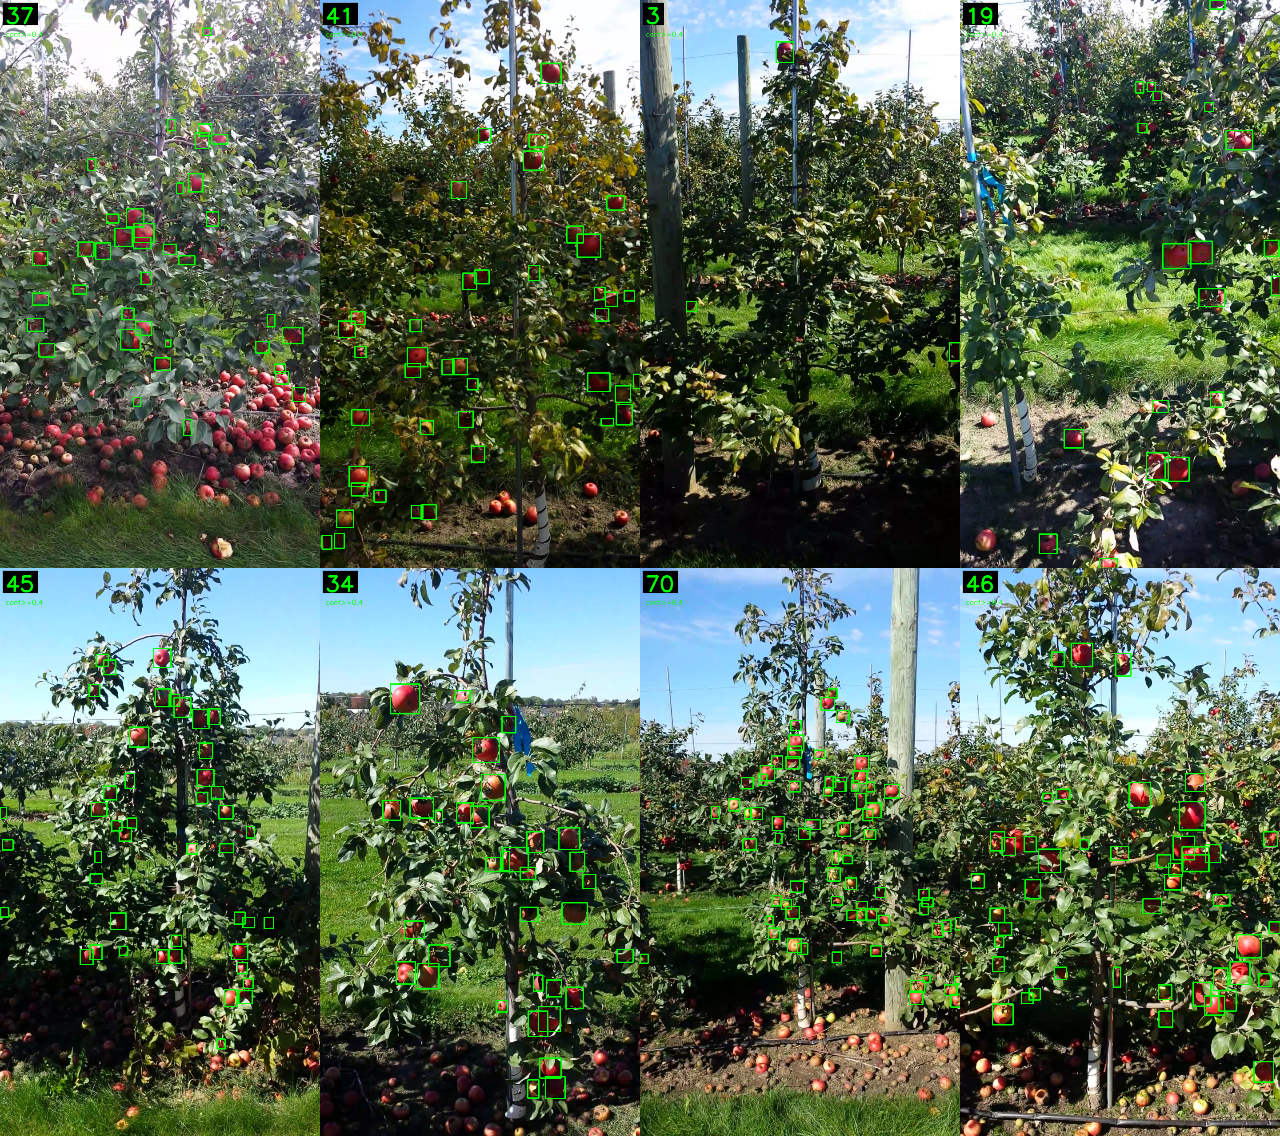

In [17]:
#@title 7. 推理可视化（最终方案：纯检测 + conf 0.40）
import json
import pathlib
import shutil
import subprocess
import sys
import time

CONF = 0.40    #@param {type:"number"}
N_SHOW = 8     #@param {type:"integer"}
# 留空 = 从 test 集抽 N_SHOW 张；也可填自己的图片或目录
SOURCE = ''    #@param {type:"string"}

WEIGHTS = globals().get('WEIGHTS')
if WEIGHTS is None or not pathlib.Path(WEIGHTS).exists():
    cands = sorted((APPLE / 'runs' / 'detection').glob('*/weights/best.pt'),
                   key=lambda p: p.stat().st_mtime)
    if cands:
        WEIGHTS = cands[-1]
    elif globals().get('PRETRAINED_WEIGHTS'):
        WEIGHTS = PRETRAINED_WEIGHTS
    else:
        raise SystemExit('找不到 best.pt：先跑 cell 5，或把权重传到 Drive 并重跑 cell 1')
WEIGHTS = pathlib.Path(WEIGHTS)
RUN_NAME = (WEIGHTS.parent.parent.name if WEIGHTS.parent.name == 'weights'
            else WEIGHTS.parent.name)

if SOURCE.strip():
    src = pathlib.Path(SOURCE.strip())
    print('推理源：', src)
else:
    test_list = [pathlib.Path(x.strip()) for x in
                 (APPLE / 'cache/detection/test.txt').read_text(encoding='utf-8').splitlines()
                 if x.strip()]
    groups = {}
    for p in test_list:
        groups.setdefault(p.name.split('_')[0], []).append(p)
    per_group = max(1, N_SHOW // max(len(groups), 1))
    sample = []
    for g in sorted(groups):
        sample.extend(groups[g][:per_group])
    sample = sample[:N_SHOW]

    src = pathlib.Path('/content/infer_demo_input')
    if src.exists():
        shutil.rmtree(src)
    src.mkdir(parents=True)
    for p in sample:
        shutil.copy2(p, src / p.name)
    print(f'从 test 抽 {len(sample)} 张：{[p.name for p in sample]}')

OUT = APPLE / 'runs' / 'detection' / f'infer_demo_{RUN_NAME}'
cmd = [sys.executable, str(APPLE / 'src' / 'infer_detection.py'),
       '--weights', str(WEIGHTS), '--source', str(src), '--out', str(OUT),
       '--conf', str(CONF)]
print(' '.join(cmd))
t0 = time.time()
r = subprocess.run(cmd, cwd=str(PROJ))
print(f'\n推理进程退出码 {r.returncode}，{time.time() - t0:.1f}s')
if r.returncode != 0:
    raise SystemExit('推理失败，看上面的日志。')

res = json.loads((OUT / 'result.json').read_text(encoding='utf-8'))
print(f'\n合计 {res["total_apples"]} 个苹果 / {res["n_images"]} 张图')
for x in res['results']:
    print(f'  {x["file"]:<44} {x["count"]:>4} 个')

from IPython.display import Image, display
montage = OUT / 'montage.png'
if montage.exists():
    display(Image(filename=str(montage), width=900))


In [18]:
#@title 8. 产物汇总 + 存回 Drive
import csv
import json
import pathlib
import shutil

RUN_NAME = globals().get('RUN_NAME') or 'colab_run'
_weights = globals().get('WEIGHTS')
if _weights:
    _w = pathlib.Path(_weights)
    RUN_DIR = _w.parent.parent if _w.parent.name == 'weights' else _w.parent
elif (APPLE / 'runs' / 'detection' / RUN_NAME).is_dir():
    RUN_DIR = APPLE / 'runs' / 'detection' / RUN_NAME
else:
    RUN_DIR = None
DRIVE_OUT = MYDRIVE / 'apple_detection' / 'results' / RUN_NAME
DRIVE_OUT.mkdir(parents=True, exist_ok=True)


def save(src, name=None):
    src = pathlib.Path(src)
    if not src.exists():
        print(f'  跳过（不存在）{src.name}')
        return
    dst = DRIVE_OUT / (name or src.name)
    if dst.exists() and src.resolve() == dst.resolve():
        print(f'  已在该目录，跳过 {src.name}')
        return
    shutil.copy2(src, dst)
    print(f'  → {dst}  {dst.stat().st_size / 1e6:.1f} MB')


print('存回 Drive：')
if RUN_DIR:
    print('run：', RUN_DIR)
    save(RUN_DIR / 'weights' / 'best.pt')
    save(RUN_DIR / 'results.csv')
    save(RUN_DIR / 'args.yaml')
    save(RUN_DIR / 'train_summary.json')
save(APPLE / 'cache/detection/eval_test.json')
save(APPLE / 'cache/detection/check_detection_montage.png')
save(APPLE / 'cache/detection/labels_meta.json')
if RUN_DIR:
    save(APPLE / 'runs' / 'detection' / f'infer_demo_{RUN_NAME}' / 'montage.png')
    save(APPLE / 'runs' / 'detection' / f'infer_demo_{RUN_NAME}' / 'result.json')

if RUN_DIR and (RUN_DIR / 'results.csv').exists():
    rows = list(csv.DictReader(open(RUN_DIR / 'results.csv', encoding='utf-8')))
    rows = [{k.strip(): v for k, v in r.items()} for r in rows]
    if rows:
        t = [float(r['time']) for r in rows]
        per = [t[0]] + [b - a for a, b in zip(t, t[1:])]
        m = sum(per) / len(per)
        print(f'\n每轮耗时：均值 {m:.1f}s  首轮 {per[0]:.1f}s  末轮 {per[-1]:.1f}s')
        if len(per) >= 6:
            print(f'  前 3 轮 {sum(per[:3]) / 3:.1f}s   后 3 轮 {sum(per[-3:]) / 3:.1f}s'
                  f'（明显变慢 = 热降频或数据加载瓶颈）')
        print(f'  60 轮线性外推 ≈ {m * 60 / 60:.1f} 分钟')

        best = None
        ts = RUN_DIR / 'train_summary.json'
        if ts.exists():
            best = json.loads(ts.read_text(encoding='utf-8')).get('best_epoch')
        last = rows[-1]
        mapkey = next(k for k in last if 'mAP50-95' in k)
        print(f'  best epoch {best}   最后一轮 val mAP50-95 {float(last[mapkey]):.4f}')

info = {
    'run_name': RUN_NAME,
    'weights': str(globals().get('WEIGHTS', '')),
    'model': globals().get('MODEL'),
    'imgsz': globals().get('IMGSZ'),
    'epochs': globals().get('EPOCHS'),
    'batch_requested': globals().get('BATCH'),
    'workers': globals().get('WORKERS'),
    'conf_infer': globals().get('CONF'),
    'note': 'batch 可能被 ultralytics 按 OOM 自动减半；看日志 Reducing to batch=',
}
(DRIVE_OUT / 'colab_run_info.json').write_text(
    json.dumps(info, ensure_ascii=False, indent=2), encoding='utf-8')
print(f'\n全部产物在：{DRIVE_OUT}')


存回 Drive：
run： /content/drive/MyDrive/apple_counting
  → /content/drive/MyDrive/apple_detection/results/apple_counting/best.pt  20.4 MB
  跳过（不存在）results.csv
  跳过（不存在）args.yaml
  跳过（不存在）train_summary.json
  → /content/drive/MyDrive/apple_detection/results/apple_counting/eval_test.json  0.0 MB
  → /content/drive/MyDrive/apple_detection/results/apple_counting/check_detection_montage.png  2.9 MB
  → /content/drive/MyDrive/apple_detection/results/apple_counting/labels_meta.json  0.0 MB
  → /content/drive/MyDrive/apple_detection/results/apple_counting/montage.png  3.4 MB
  → /content/drive/MyDrive/apple_detection/results/apple_counting/result.json  0.0 MB

全部产物在：/content/drive/MyDrive/apple_detection/results/apple_counting


## 排查表

| 现象 | 处理 |
|---|---|
| 找不到数据根 | 把 cell 1 的 `DATA_ROOT` 写成 Drive 上的真实路径（含 `detection/` 与 `test_data/`） |
| 找不到代码包 | 把 `apple_detection_code.zip` 放进 `MyDrive/apple_detection/`，或上传到 `/content/` |
| 训练 OOM | 先把 `BATCH` 降到 4，再把 `IMGSZ` 降到 960。日志里 `Reducing to batch=` 是真正生效的值 |
| 权重下载失败 | `!wget -O /content/apple_detection/yolo26s.pt https://github.com/ultralytics/assets/releases/download/v8.4.0/yolo26s.pt` |
| 想用 4090 上训好的权重 | 传到 `MyDrive/apple_detection/` 后重跑 cell 1 自动认领；也可在 cell 6 的 `EXTERNAL_WEIGHTS` 手动填路径。跳过 cell 5，直接跑 cell 6/7 |
| Colab 断线 | 重连后从 cell 3 开始重跑（同一会话内本地数据还在）；Drive 上的结果不会丢 |
| 推理阈值 | 默认 `CONF=0.40` 是项目在 MinneApple test 上标定的最终方案；换目标域要重新标定 |

**纪律**：val 只做粗筛，关键结论必须回 test；`best.pt` 按 mAP50-95 选，
而项目的靶子是 AP_small —— 选型要回 `eval_detection.py` 看 size-bucketed AP。
